# Projet 1 — Réseaux de Neurones Artificiels (ANN) : Classification
### Classification du cancer du sein (WDBC) par un ANN optimisé par la méthode de Taguchi
## Partie 1 — Validation n°1 (≈ 45 % du projet)

**Article de référence :** *Artificial Neural Network with Taguchi Method for Robust Classification Model to Improve Classification Accuracy of Breast Cancer* (2021) — https://pmc.ncbi.nlm.nih.gov/articles/PMC7924699/
**Données :** UCI — Breast Cancer Wisconsin (Diagnostic) — https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
569 observations, 30 variables explicatives, 2 classes : **bénin (B)** et **malin (M)**.

#### Contenu de cette partie
1. Chargement et exploration des données
2. Prétraitement (encodage, partition, normalisation)
3. Premier modèle ANN (configuration de l'article) et évaluation sur l'ensemble de test
4. Conception du plan d'expériences de Taguchi (tableau orthogonal L9, rapport S/N) — **préparé, exécution en partie 2**
5. Bilan et travail restant

## 0. Imports et configuration

In [1]:
import os, copy, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, roc_auc_score,
                             roc_curve, classification_report, log_loss)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("OK")

OK


## 1. Chargement et exploration des données

In [2]:
DATA_PATH = "data/wdbc.csv"
if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
else:
    # Secours : fichier brut UCI (id, diagnostic, 30 variables, sans en-tête)
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
    base = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
            "concavity", "concave points", "symmetry", "fractal dimension"]
    cols = ["id", "diagnosis"] + [f"mean {b}" for b in base] + [f"{b} error" for b in base] + [f"worst {b}" for b in base]
    df = pd.read_csv(url, header=None, names=cols).drop(columns="id")

print("Dimensions :", df.shape)
df.head()

Dimensions : (569, 31)


,diagnosis,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print("\nRépartition des classes :")
print(df["diagnosis"].value_counts().rename({"B": "Bénin (B)", "M": "Malin (M)"}))
df.describe().T.head(10)

Valeurs manquantes : 0

Répartition des classes :
diagnosis
Bénin (B)    357
Malin (M)    212
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.78000,28.11000
mean texture,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.80000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.10000,188.50000
mean area,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.70000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.10530,0.16340
mean compactness,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.13040,0.34540
mean concavity,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.13070,0.42680
mean concave points,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.07400,0.20120
mean symmetry,569.0,0.181162,0.027414,0.10600,0.16190,0.17920,0.19570,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.04996,0.05770,0.06154,0.06612,0.09744


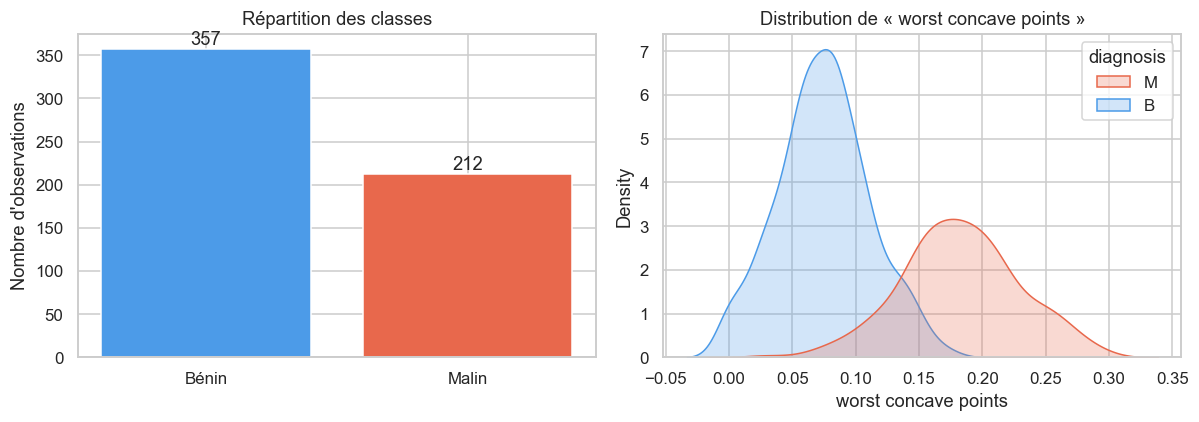

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = df["diagnosis"].value_counts()
axes[0].bar(["Bénin", "Malin"], [counts["B"], counts["M"]], color=["#4C9BE8", "#E8684C"])
for i, v in enumerate([counts["B"], counts["M"]]):
    axes[0].text(i, v + 5, str(v), ha="center")
axes[0].set_title("Répartition des classes")
axes[0].set_ylabel("Nombre d'observations")

sns.kdeplot(data=df, x="worst concave points", hue="diagnosis", fill=True, ax=axes[1],
            palette={"B": "#4C9BE8", "M": "#E8684C"})
axes[1].set_title("Distribution de « worst concave points »")
plt.tight_layout(); plt.savefig("figures/01_classes.png", bbox_inches="tight"); plt.show()

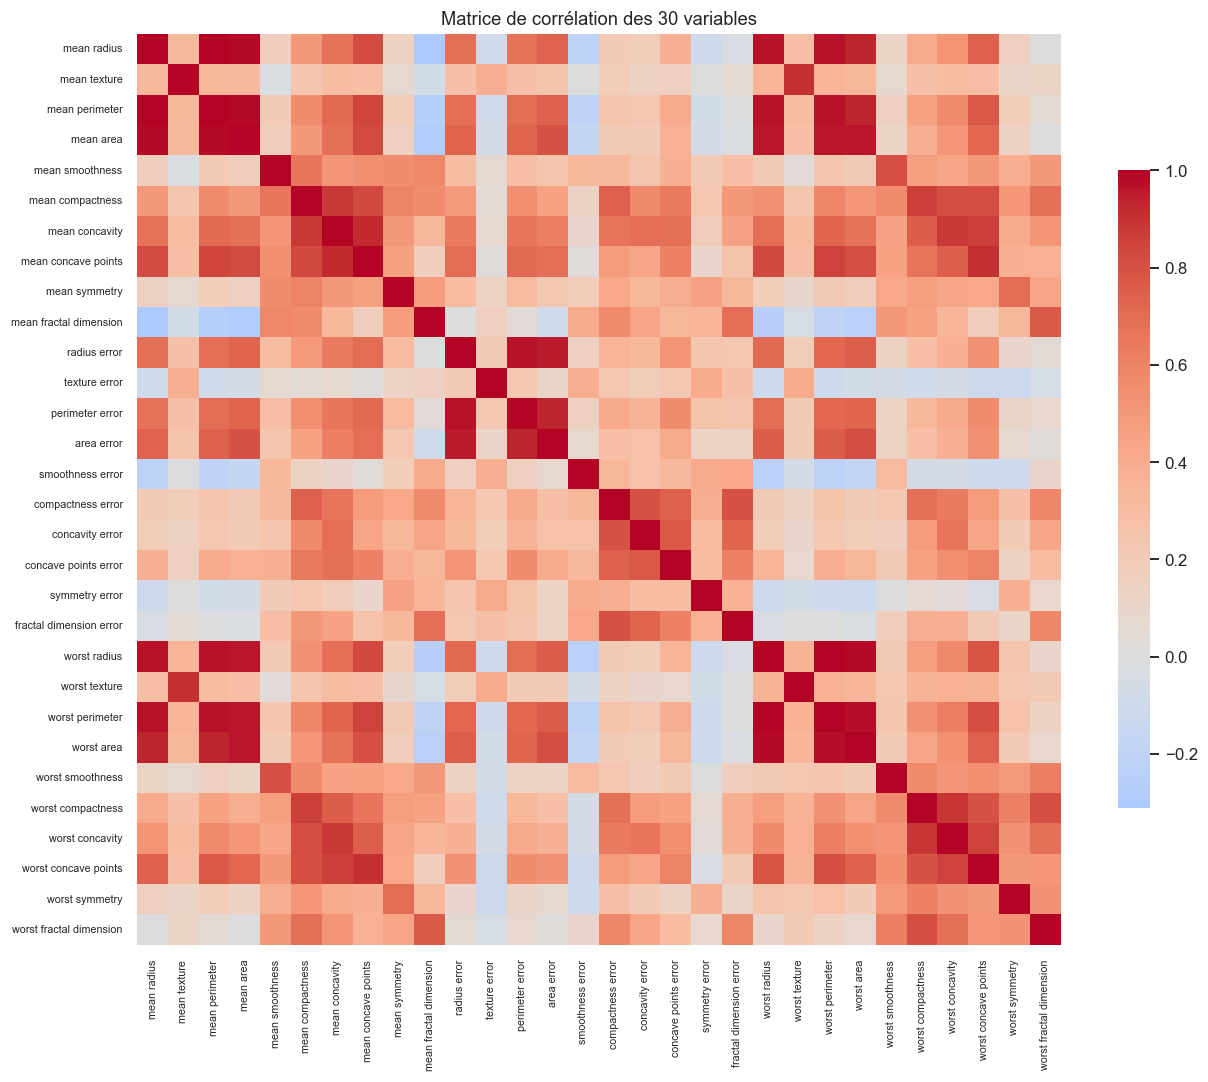

10 variables les plus corrélées au diagnostic (|r|) :
worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660
dtype: float64


In [5]:
X_all = df.drop(columns="diagnosis")
corr = X_all.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True, cbar_kws={"shrink": .7})
plt.title("Matrice de corrélation des 30 variables")
plt.xticks(fontsize=7); plt.yticks(fontsize=7)
plt.tight_layout(); plt.savefig("figures/02_correlation.png", bbox_inches="tight"); plt.show()

y_tmp = (df["diagnosis"] == "M").astype(int)
top = X_all.corrwith(y_tmp).abs().sort_values(ascending=False).head(10)
print("10 variables les plus corrélées au diagnostic (|r|) :")
print(top.round(3))

## 2. Prétraitement
- Encodage de la cible : **Malin = 1 (classe positive)**, Bénin = 0.
- Partition stratifiée **entraînement / validation / test** (la validation sert à l'arrêt précoce et à la sélection Taguchi ; le test n'est utilisé qu'à la fin).
- Normalisation `StandardScaler` **ajustée uniquement sur l'entraînement** (pas de fuite d'information).

In [6]:
X = df.drop(columns="diagnosis").values.astype(float)
y = (df["diagnosis"] == "M").astype(int).values
feature_names = df.drop(columns="diagnosis").columns.tolist()

def split_data(X, y, train=0.70, val=0.15, test=0.15, seed=SEED):
    # Partition stratifiée train/val/test + normalisation ajustée sur train
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, train_size=train, stratify=y, random_state=seed)
    rel_test = test / (val + test)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=rel_test, stratify=y_tmp, random_state=seed)
    sc = StandardScaler().fit(X_tr)
    return sc.transform(X_tr), sc.transform(X_va), sc.transform(X_te), y_tr, y_va, y_te

X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(X, y)
print(f"Entraînement : {X_tr.shape[0]} | Validation : {X_va.shape[0]} | Test : {X_te.shape[0]}")

Entraînement : 398 | Validation : 85 | Test : 86


## 3. Modèle ANN
Comme dans l'article : réseau *feed-forward* à **une couche cachée**, 30 entrées, sortie probabiliste (softmax/sigmoïde), fonction de coût **entropie croisée**, entraînement par descente de gradient, **arrêt précoce** sur l'erreur de validation (on conserve les meilleurs poids).

La fonction `train_ann` entraîne époque par époque (`partial_fit`) pour suivre les courbes d'apprentissage.

In [7]:
def train_ann(X_tr, y_tr, X_va, y_va, hidden=15, lr=0.01, activation="logistic", alpha=1e-4, batch=32,
              seed=SEED, max_epochs=300, patience=25, return_history=False):
    clf = MLPClassifier(hidden_layer_sizes=(hidden,), activation=activation, solver="adam",
                        learning_rate_init=lr, batch_size=batch, alpha=alpha,
                        max_iter=1, warm_start=True, random_state=seed)
    classes = np.array([0, 1])
    best_loss, best_model, wait = np.inf, None, 0
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(max_epochs):
        clf.partial_fit(X_tr, y_tr, classes=classes)
        p_va = clf.predict_proba(X_va)[:, 1]
        vl = log_loss(y_va, p_va, labels=[0, 1])
        if return_history:
            p_tr = clf.predict_proba(X_tr)[:, 1]
            hist["train_loss"].append(log_loss(y_tr, p_tr, labels=[0, 1]))
            hist["val_loss"].append(vl)
            hist["train_acc"].append(accuracy_score(y_tr, (p_tr >= .5).astype(int)))
            hist["val_acc"].append(accuracy_score(y_va, (p_va >= .5).astype(int)))
        if vl < best_loss - 1e-5:
            best_loss, best_model, wait, best_epoch = vl, copy.deepcopy(clf), 0, epoch + 1
        else:
            wait += 1
            if wait >= patience:
                break
    best_model.best_epoch_ = best_epoch
    return (best_model, hist) if return_history else best_model

def metrics(model, X_, y_):
    proba = model.predict_proba(X_)[:, 1]
    pred = (proba >= .5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, pred, labels=[0, 1]).ravel()
    return {"accuracy": (tp + tn) / len(y_),
            "sensitivity": tp / (tp + fn),       # rappel classe maligne
            "specificity": tn / (tn + fp),
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "f1": f1_score(y_, pred),
            "auc": roc_auc_score(y_, proba)}

def train_with(p, X_tr, y_tr, X_va, y_va, seed=SEED, **kw):
    # Entraîne un ANN avec un dictionnaire de paramètres Taguchi
    return train_ann(X_tr, y_tr, X_va, y_va, hidden=p["A_neurones"], lr=p["B_lr"],
                     activation=p["C_activation"], alpha=p["D_alpha"], seed=seed, **kw)

# Modèle de départ (configuration de l'article : 15 neurones cachés, sigmoïde)
t0 = time.time()
base_model, base_hist = train_ann(X_tr, y_tr, X_va, y_va, hidden=15, lr=0.01, activation="logistic",
                                  batch=32, return_history=True)
print(f"Meilleure époque : {base_model.best_epoch_}  ({time.time()-t0:.1f}s)")
print("Validation :", {k: round(float(v), 4) for k, v in metrics(base_model, X_va, y_va).items()})

Meilleure époque : 12  (0.4s)
Validation : {'accuracy': 0.9765, 'sensitivity': 0.9375, 'specificity': 1.0, 'precision': 1.0, 'f1': 0.9677, 'auc': 0.9965}


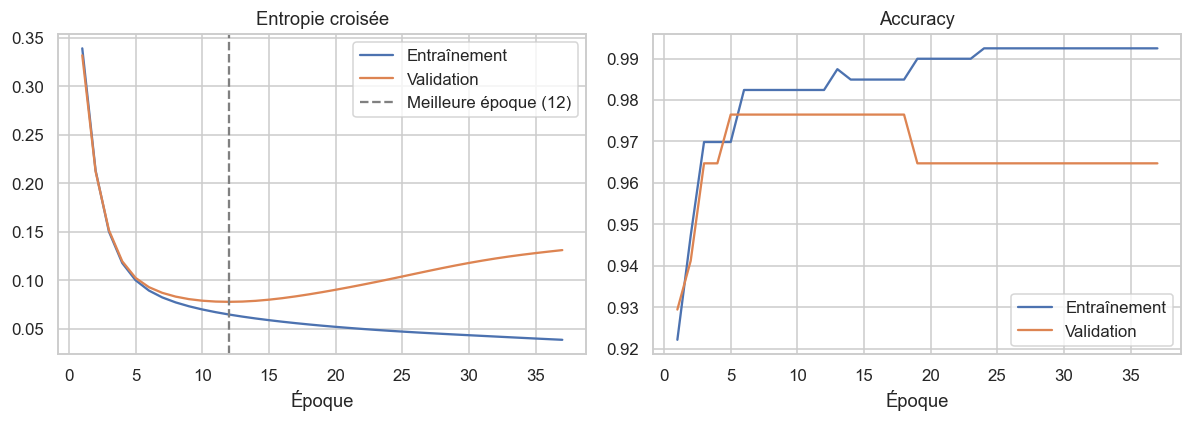

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ep = np.arange(1, len(base_hist["train_loss"]) + 1)
ax[0].plot(ep, base_hist["train_loss"], label="Entraînement")
ax[0].plot(ep, base_hist["val_loss"], label="Validation")
ax[0].axvline(base_model.best_epoch_, ls="--", c="gray", label=f"Meilleure époque ({base_model.best_epoch_})")
ax[0].set_title("Entropie croisée"); ax[0].set_xlabel("Époque"); ax[0].legend()
ax[1].plot(ep, base_hist["train_acc"], label="Entraînement")
ax[1].plot(ep, base_hist["val_acc"], label="Validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Époque"); ax[1].legend()
plt.tight_layout(); plt.savefig("figures/03_courbes_apprentissage.png", bbox_inches="tight"); plt.show()

### 3.1 Évaluation du premier modèle sur l'ensemble de test
Le modèle de départ reprend la configuration de l'article : **15 neurones cachés, activation sigmoïde**. L'ensemble de test n'a servi à aucun réglage.

Résultats sur l'ensemble de TEST (modèle de départ) :
  accuracy    : 0.9884
  sensitivity : 1.0000
  specificity : 0.9815
  precision   : 0.9697
  f1          : 0.9846
  auc         : 0.9994


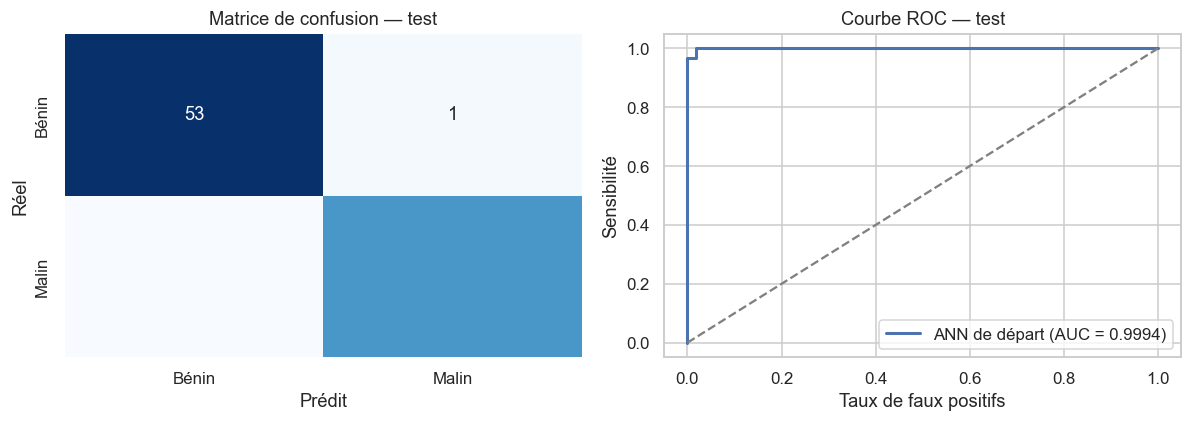

In [9]:
m_test = metrics(base_model, X_te, y_te)
print("Résultats sur l'ensemble de TEST (modèle de départ) :")
for k, v in m_test.items():
    print(f"  {k:12s}: {v:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cm = confusion_matrix(y_te, base_model.predict(X_te), labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["Bénin", "Malin"], yticklabels=["Bénin", "Malin"])
ax[0].set_xlabel("Prédit"); ax[0].set_ylabel("Réel"); ax[0].set_title("Matrice de confusion — test")
fpr, tpr, _ = roc_curve(y_te, base_model.predict_proba(X_te)[:, 1])
ax[1].plot(fpr, tpr, lw=2, label=f"ANN de départ (AUC = {m_test['auc']:.4f})"); ax[1].plot([0, 1], [0, 1], "--", c="gray")
ax[1].set_xlabel("Taux de faux positifs"); ax[1].set_ylabel("Sensibilité"); ax[1].set_title("Courbe ROC — test"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/04_test_modele_depart.png", bbox_inches="tight"); plt.show()

### 3.2 Stabilité du modèle de départ (10 exécutions)
Un seul découpage des données peut donner un résultat chanceux. On répète l'entraînement 10 fois avec des partitions et initialisations différentes : c'est cette **variabilité** que la méthode de Taguchi cherchera à réduire (robustesse).

In [10]:
ref = {"A_neurones": 15, "B_lr": 0.01, "C_activation": "logistic", "D_alpha": 1e-4}
rows = []
for r in range(10):
    Xtr_, Xva_, Xte_, ytr_, yva_, yte_ = split_data(X, y, .70, .15, .15, seed=1000 + r)
    m = train_with(ref, Xtr_, ytr_, Xva_, yva_, seed=1000 + r)
    rows.append({"exécution": r + 1, **{k: v for k, v in metrics(m, Xte_, yte_).items()}})
runs10 = pd.DataFrame(rows)
runs10.to_csv("results/modele_depart_10_executions.csv", index=False)
print(runs10.drop(columns="exécution").agg(["mean", "std"]).T.round(4))
runs10.round(4)

               mean     std
accuracy     0.9744  0.0211
sensitivity  0.9500  0.0422
specificity  0.9889  0.0179
precision    0.9812  0.0296
f1           0.9648  0.0292
auc          0.9929  0.0081


,exécution,accuracy,sensitivity,specificity,precision,f1,auc
0,1,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
1,2,0.9767,0.9688,0.9815,0.9688,0.9688,0.9838
2,3,0.9419,0.8750,0.9815,0.9655,0.9180,0.9954
3,4,0.9767,0.9688,0.9815,0.9688,0.9688,0.9983
4,5,0.9884,0.9688,1.0000,1.0000,0.9841,0.9844
5,6,0.9884,0.9688,1.0000,1.0000,0.9841,0.9948
6,7,0.9884,0.9688,1.0000,1.0000,0.9841,0.9988
7,8,0.9419,0.9375,0.9444,0.9091,0.9231,0.9769
8,9,0.9884,0.9688,1.0000,1.0000,0.9841,0.9971
9,10,0.9535,0.8750,1.0000,1.0000,0.9333,0.9994


## 4. Conception du plan d'expériences de Taguchi (préparation de la partie 2)

La méthode de Taguchi remplace le plan factoriel complet (3⁴ = 81 combinaisons) par un **tableau orthogonal L9(3⁴)** : 9 essais suffisent pour estimer l'effet de 4 facteurs à 3 niveaux.

| Facteur | Niveau 1 | Niveau 2 | Niveau 3 |
|---|---|---|---|
| A — Neurones cachés | 10 | 15 | 20 |
| B — Taux d'apprentissage (Adam) | 0,001 | 0,01 | 0,05 |
| C — Fonction d'activation | logistic (sigmoïde) | tanh | relu |
| D — Régularisation L2 (alpha) | 0,0001 | 0,01 | 0,1 |

**Critère de robustesse :** chaque essai sera répété (validation croisée 5-fold × 3 = 15 mesures) et résumé par le rapport signal/bruit « plus c'est grand, mieux c'est » :

$$ S/N = -10\,\log_{10}\left(\frac{1}{n}\sum_{i=1}^{n}\frac{1}{y_i^2}\right) $$

In [11]:
L9 = np.array([[1,1,1,1],[1,2,2,2],[1,3,3,3],
               [2,1,2,3],[2,2,3,1],[2,3,1,2],
               [3,1,3,2],[3,2,1,3],[3,3,2,1]])
levels = {"A_neurones": [10, 15, 20],
          "B_lr": [0.001, 0.01, 0.05],
          "C_activation": ["logistic", "tanh", "relu"],
          "D_alpha": [1e-4, 1e-2, 1e-1]}
factors = list(levels.keys())

for i in range(4):
    for j in range(i + 1, 4):
        assert len(set(zip(L9[:, i], L9[:, j]))) == 9
print("Tableau L9(3^4) orthogonal vérifié : chaque couple de niveaux apparaît une fois par paire de colonnes.")

def sn_larger_better(y):
    y = np.asarray(y)
    return -10 * np.log10(np.mean(1.0 / y**2))

print(f"Exemple : S/N des 10 exécutions du modèle de départ = {sn_larger_better(runs10['accuracy']):.3f} dB")

plan = pd.DataFrame([{"essai": k + 1, **{f: levels[f][l - 1] for f, l in zip(factors, row)}} for k, row in enumerate(L9)])
plan.to_csv("results/plan_taguchi_L9.csv", index=False)
plan

Tableau L9(3^4) orthogonal vérifié : chaque couple de niveaux apparaît une fois par paire de colonnes.
Exemple : S/N des 10 exécutions du modèle de départ = -0.231 dB


,essai,A_neurones,B_lr,C_activation,D_alpha
0,1,10,0.001,logistic,0.0001
1,2,10,0.010,tanh,0.0100
2,3,10,0.050,relu,0.1000
3,4,15,0.001,tanh,0.1000
4,5,15,0.010,relu,0.0001
5,6,15,0.050,logistic,0.0100
6,7,20,0.001,relu,0.0100
7,8,20,0.010,logistic,0.1000
8,9,20,0.050,tanh,0.0001


## 5. Bilan de la partie 1 et travail restant

**Réalisé (≈ 45 %) :**
- Données chargées et explorées : 569 observations, aucune valeur manquante, classes déséquilibrées (357 B / 212 M), fortes corrélations entre variables de taille (radius, perimeter, area).
- Prétraitement : cible encodée (malin = 1), partition stratifiée 70/15/15, normalisation ajustée sur l'entraînement uniquement.
- Premier ANN (configuration de l'article : 15 neurones, sigmoïde, arrêt précoce) : **98,8 % d'accuracy** sur l'ensemble de test de référence (sensibilité 100 %, AUC 0,999). Sur 10 exécutions, la moyenne est **97,4 % ± 2,1** : le résultat dépend du découpage, d'où l'intérêt d'une optimisation robuste (Taguchi).
- Plan d'expériences de Taguchi L9(3⁴) conçu et vérifié, critère S/N défini.

**Reste à faire (partie 2) :**
1. Exécuter les 9 essais Taguchi, calculer les S/N, tableau des réponses et graphique des effets principaux.
2. ANOVA (contribution de chaque facteur) et expérience de confirmation.
3. Expérience 2 : choix de la partition (50/25/25, 60/20/20, 70/15/15, 80/10/10).
4. Évaluation finale : 30 exécutions + validation croisée 10-fold.
5. Comparaison avec d'autres classifieurs (SVM, régression logistique, k-NN, forêt aléatoire…) et avec l'article.